# DATA 621 Homework 3: Crime Risk Prediction with Logistic Regression

## Project Objective
This project's objective is to build binary logistic regression models using the crime training data to predict whether a neighborhood's crime rate is above the median (`target = 1`) or not (`target = 0`). Evaluate and select a model, then use it to generate classifications and predicted probabilities for the evaluation data, applying a 0.5 classification threshold.

# 1. Load Data/EDA
## 1.1 Dataset Overview & Data Quality Assessment:

To complete this assignement the datasets were first uploaded to the group GitHub repository and then loaded directly from the raw GitHub URL using `pandas`. This ensures the notebook is 100% reproducible without requiring local file downloads.

We started by importing the core Python libraries needed for data manipulation and visualization, and loading the training dataset directly from the GitHub repository.

Before we model, we must verify the size, scope, and integrity of our data. A model built on incomplete data cannot be trusted in production.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for executive-ready visuals
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load the datasets
train_url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/main/homeworks/hw03/data/crime-training-data_modified.csv"
train_df = pd.read_csv(train_url)

# 1. Size and Scope
print(f"Dataset Size: {train_df.shape[0]} neighborhoods and {train_df.shape[1]} variables.")

# 2. Data Quality (Missing Values)
missing_data = train_df.isnull().sum().sum()
if missing_data == 0:
    print("Data Quality: Excellent. There are 0 missing values across all columns. No imputation is required.")
else:
    print(f"Data Quality Warning: {missing_data} missing values detected.")

Dataset Size: 466 neighborhoods and 13 variables.
Data Quality: Excellent. There are 0 missing values across all columns. No imputation is required.


## 1.2 The Target Variable & Baseline Statistics

Our goal is to predict whether a neighborhood is at risk for high crime (`target = 1`). We need to establish if our data is skewed toward one outcome, and look at the baseline averages for key neighborhood metrics.

In [2]:
# Target Variable Balance
target_counts = train_df['target'].value_counts(normalize=True) * 100
print(f"Target Balance: {target_counts[0]:.1f}% Low Crime (0) | {target_counts[1]:.1f}% High Crime (1)")

# Executive Summary Stats for Key Variables
key_vars = ['nox', 'age', 'tax', 'dis', 'medv']
summary_stats = train_df[key_vars].agg(['mean', 'median', 'std']).round(2).T
print("\n--- Baseline Neighborhood Statistics ---")
display(summary_stats)

Target Balance: 50.9% Low Crime (0) | 49.1% High Crime (1)

--- Baseline Neighborhood Statistics ---


,mean,median,std
nox,0.55,0.54,0.12
age,68.37,77.15,28.32
tax,409.50,334.50,167.90
dis,3.80,3.19,2.11
medv,22.59,21.20,9.24


The data is almost perfectly split (51% low crime, 49% high crime). This is ideal. We will not need to use complex class-balancing techniques (like oversampling) that can distort model accuracy.

We observe wide variances in housing age (`age`) and property taxes (`tax`). The median and mean for variables like `dis` differ noticeably, indicating skew in the data that we may need to transform before modeling.

## 1.3 Visualizing Key Drivers of Crime

Rather than plotting every single variable, we focus on the features that show the clearest separation between high-crime and low-crime neighborhoods.

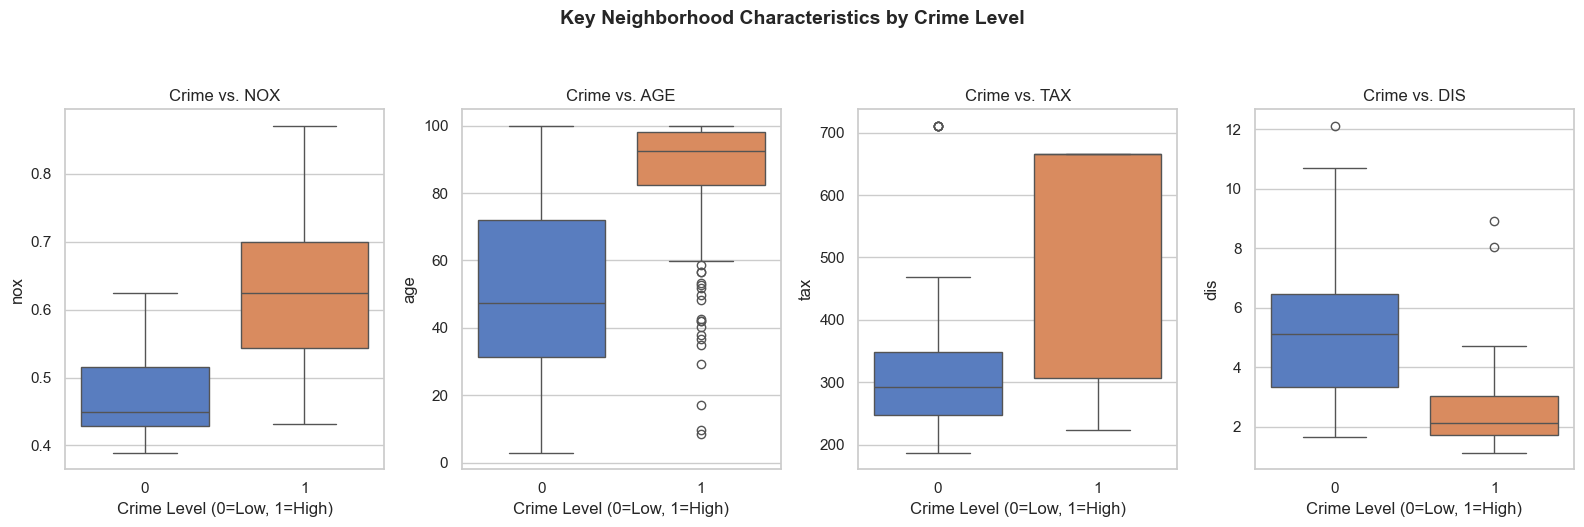

In [3]:
# Select top features to highlight
features_to_plot = ['nox', 'age', 'tax', 'dis']
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, col in enumerate(features_to_plot):
    sns.boxplot(x='target', y=col, data=train_df, ax=axes[i], palette="muted", hue='target', legend=False)
    axes[i].set_title(f"Crime vs. {col.upper()}", fontsize=12)
    axes[i].set_xlabel("Crime Level (0=Low, 1=High)")

plt.suptitle("Key Neighborhood Characteristics by Crime Level", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The boxplots reveal stark contrasts. High-crime neighborhoods (1) are heavily associated with:

- Significantly higher nitrogen oxide pollution (nox).

- Much older housing stock (age).

- Higher property tax rates (tax).

- Closer proximity to urban employment centers (dis is lower).

## 1.4 Correlation & Redundancy (Multicollinearity)

Finally, we must check how strongly these variables correlate with crime, and more importantly, if any of our variables are redundant. Feeding a model highly redundant data causes instability and makes business interpretation difficult.

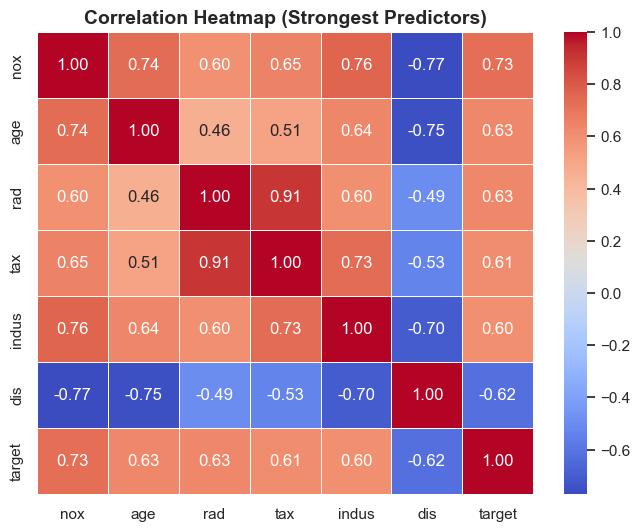

--- Redundancy Alert ---
Correlation between TAX and RAD (Highway Access): 0.91


In [4]:
# Compute correlation matrix
corr_matrix = train_df.corr()

# Isolate correlations with the target
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)

# Plot a focused heatmap of the strongest relationships
plt.figure(figsize=(8, 6))
top_corr_vars = target_corr[abs(target_corr) > 0.5].index.tolist() + ['target']
sns.heatmap(train_df[top_corr_vars].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Strongest Predictors)", fontsize=14, fontweight='bold')
plt.show()

print("--- Redundancy Alert ---")
print(f"Correlation between TAX and RAD (Highway Access): {train_df['tax'].corr(train_df['rad']):.2f}")

Pollution (nox, 0.73) and Highway Accessibility (rad, 0.63) are our strongest single predictors of high crime.

Property tax rates (tax) and highway accessibility (rad) have a massive 0.91 correlation. They are essentially telling us the same thing, likely identifying specific urban zones. Including both in our logistic regression will confuse the model. We should drop one or combine them in the data preparation phase.

# 2. Data preparation

The training dataset contains 466 observations and 12 predictor variables, while the evaluation dataset contains 40 observations. An examination of missing values confirmed that all variables are complete, so no imputation or deletion of records is necessary.

To prepare the data for the logistic regression, we will separate the predictors from the target variable and divide the labeled observations into training and validation subsets. This allows us to evaluate model performance on observations not used during model fitting.

We standardized all 12 predictor variables to place them on comparable scales. We retained the original predictors for initial modeling and documented the strong correlation between tax and rad for consideration during model selection.

In [5]:


import pandas as pd
from sklearn.model_selection import train_test_split

# Load datasets directly from the group GitHub repository
base_url = (
    "https://raw.githubusercontent.com/alinsimon/"
    "data621-data-mining/main/homeworks/hw03/data/"
)

train_df = pd.read_csv(
    base_url + "crime-training-data_modified.csv"
)

eval_df = pd.read_csv(
    base_url + "crime-evaluation-data_modified.csv"
)

print("Training dataset:", train_df.shape)
print("Evaluation dataset:", eval_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nMissing values:")
print("Training:", train_df.isna().sum().sum())
print("Evaluation:", eval_df.isna().sum().sum())



Training dataset: (466, 13)
Evaluation dataset: (40, 12)

Training columns:
['zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv', 'target']

Missing values:
Training: 0
Evaluation: 0


In [6]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = train_df.drop(columns=["target"])
y = train_df["target"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=621,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Validation observations:", X_val.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training observations: 372
Validation observations: 94

Training target distribution:
target
0    0.508065
1    0.491935
Name: proportion, dtype: float64

Validation target distribution:
target
0    0.510638
1    0.489362
Name: proportion, dtype: float64


## Training and Validation Split 

The dataset was divided into 80% training data (372 observations) and 20% validation data (94 observations). A stratified split was used to maintain approximately equal proportions of the target variable across both datasets. 

The training dataset contains 50.81% lower-crime neighborhoods and 49.19% higher-crime neighborhoods. Similarly, the validation dataset contains 51.06% lower-crime neighborhoods and 48.94% higher-crime neighborhoods.

These results indicate that the target variable is relatively balanced and that the stratified split successfully preserved its distribution. This approach allows us to evaluate the logistic regression models on unseen observations while reducing the risk of differences in class proportions affecting our comparisons.

In [7]:

from sklearn.preprocessing import StandardScaler

# Initialize the standard scaler
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the same scaling to validation data
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

# Compare original and scaled values
print("Original training data:")
display(X_train.head())

print("\nScaled training data:")
display(X_train_scaled.head())

# Verify scaling
print("\nScaled variable means:")
print(X_train_scaled.mean().round(2))

print("\nScaled variable standard deviations:")
print(X_train_scaled.std(ddof=0).round(2))


Original training data:


,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
256,0.0,25.65,0,0.581,6.004,84.1,2.1974,2,188,19.1,14.27,20.3
328,0.0,8.14,0,0.538,6.096,96.9,3.7598,4,307,21.0,20.34,13.5
195,0.0,6.91,0,0.448,6.211,6.5,5.7209,3,233,17.9,7.44,24.7
7,0.0,18.10,0,0.693,4.519,100.0,1.6582,24,666,20.2,36.98,7.0
86,0.0,19.58,0,0.605,6.943,97.4,1.8773,5,403,14.7,4.59,41.3



Scaled training data:


,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
256,-0.497148,2.103399,-0.262613,0.217804,-0.409782,0.548648,-0.758404,-0.867234,-1.315361,0.319913,0.238647,-0.243696
328,-0.497148,-0.426880,-0.262613,-0.149353,-0.281194,1.008123,-0.018701,-0.637290,-0.608216,1.178360,1.087774,-0.980552
195,-0.497148,-0.604621,-0.262613,-0.917821,-0.120460,-2.236924,0.909763,-0.752262,-1.047953,-0.222263,-0.716797,0.233093
7,-0.497148,1.012388,-0.262613,1.174120,-2.485348,1.119403,-1.013683,1.662147,1.525101,0.816909,3.415531,-1.684900
86,-0.497148,1.226255,-0.262613,0.422729,0.902647,1.026072,-0.909952,-0.522318,-0.037747,-1.668068,-1.115481,2.031889



Scaled variable means:
zn        -0.0
indus      0.0
chas      -0.0
nox        0.0
rm         0.0
age        0.0
dis       -0.0
rad        0.0
tax       -0.0
ptratio    0.0
lstat      0.0
medv      -0.0
dtype: float64

Scaled variable standard deviations:
zn         1.0
indus      1.0
chas       1.0
nox        1.0
rm         1.0
age        1.0
dis        1.0
rad        1.0
tax        1.0
ptratio    1.0
lstat      1.0
medv       1.0
dtype: float64


### Feature Standardization

All 12 predictor variables were standardized using `StandardScaler` from scikit-learn. Standardization transforms each variable by subtracting its training-set mean and dividing by its training-set standard deviation.

The scaler was fitted exclusively on the training subset and subsequently applied to the validation subset to prevent data leakage.

The resulting standardized training variables have means approximately equal to zero and standard deviations equal to one. This transformation places the predictors on comparable scales, supports numerical stability, and helps ensure that differences in measurement units do not disproportionately affect regularized logistic regression models.

The original target variable was not standardized because it represents a binary classification outcome.

In [8]:

# Prepare the evaluation dataset using the same scaler

# Match the predictor order used during training
X_eval = eval_df[X_train.columns].copy()

# Apply the scaler fitted on the training subset
X_eval_scaled = pd.DataFrame(
    scaler.transform(X_eval),
    columns=X_eval.columns,
    index=X_eval.index
)

print("Evaluation observations:", X_eval_scaled.shape[0])
print("Evaluation predictors:", X_eval_scaled.shape[1])

print("\nFirst five standardized evaluation records:")
display(X_eval_scaled.head())


Evaluation observations: 40
Evaluation predictors: 12

First five standardized evaluation records:


,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,-0.497148,-0.58150,-0.262613,-0.738512,1.240888,-0.276973,0.552884,-0.867234,-0.994472,-0.267445,-1.193819,1.316705
1,-0.497148,-0.42688,-0.262613,-0.149353,-0.281194,0.563006,0.313702,-0.637290,-0.608216,1.178360,-0.322309,-0.471255
2,-0.497148,-0.42688,-0.262613,-0.149353,0.276483,0.918382,0.310293,-0.637290,-0.608216,1.178360,0.033009,-0.449582
3,-0.497148,-0.42688,-0.262613,-0.149353,-0.485257,0.473265,0.090285,-0.637290,-0.608216,1.178360,2.118758,-1.013061
4,-0.497148,-0.74190,-0.262613,-0.482356,-0.625026,-0.980545,0.063867,-0.522318,-0.774603,0.365095,-0.530744,-0.167843


### Multicollinearity and Predictor Selection

The exploratory analysis identified a strong positive correlation of 0.91 between property tax rates (`tax`) and highway accessibility (`rad`). This relationship suggests potential multicollinearity, which may affect the stability and interpretation of logistic regression coefficients.

Both predictors were retained during the initial data preparation stage to preserve information for the baseline model. However, their strong correlation should be considered during model development.

Alternative models may exclude one of these predictors to determine whether a simpler model produces comparable or improved predictive performance. This approach allows predictor selection to be guided by model evaluation rather than correlation alone.

### Evaluation Dataset Preparation

The 40 evaluation observations were prepared using the same standardization parameters learned from the training subset. This ensures that the training, validation, and evaluation datasets use consistent predictor transformations.

The evaluation dataset was not used to fit the scaler or train the model, preventing information leakage. The standardized evaluation data will be used to generate predicted probabilities and crime-risk classifications after the final logistic regression model is selected.

# 3. Build models

# 4. Model selection and predictions

# 5. Final report prep